# LightGBM Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Light Gradient Boosting Machine (LightGBM) is an efficient gradient boosting framework designed for high-performance machine learning on structured datasets.

This notebook develops a LightGBM classifier using the PCA-transformed applicant dataset to predict loan default.

The objectives are to:

- Train a LightGBM classifier.
- Predict applicant default probabilities.
- Evaluate classification performance.
- Analyze feature importance.
- Compare LightGBM with all previously developed models.

# Import Required Libraries

The following libraries are required for model development, evaluation, and visualization.

In [2]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets created during feature engineering are loaded for model training and evaluation.

In [3]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train LightGBM Model

A LightGBM classifier is trained using the PCA-transformed training dataset.

Class imbalance is handled using the `scale_pos_weight` parameter.

In [4]:
# ============================================================
# Train LightGBM
# ============================================================

scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

lgbm_model = LGBMClassifier(

    n_estimators=300,

    learning_rate=0.05,

    max_depth=6,

    subsample=0.8,

    colsample_bytree=0.8,

    scale_pos_weight=scale_pos_weight,

    random_state=42

)

lgbm_model.fit(
    X_train,
    y_train
)

print("LightGBM model trained successfully.")

[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.032732 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 30345
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 119
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.080729 -> initscore=-2.432482
[LightGBM] [Info] Start training from score -2.432482
LightGBM model trained successfully.


# Generate Predictions

The trained LightGBM classifier predicts both class labels and the probability of default.

In [5]:
# ============================================================
# Predictions
# ============================================================

y_pred = lgbm_model.predict(X_test)

y_prob = lgbm_model.predict_proba(X_test)[:,1]

# Model Evaluation

The LightGBM classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [6]:
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

auc = roc_auc_score(y_test,y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.720485
1,Precision,0.173555
2,Recall,0.654582
3,F1 Score,0.274366
4,ROC AUC,0.754543


# Confusion Matrix

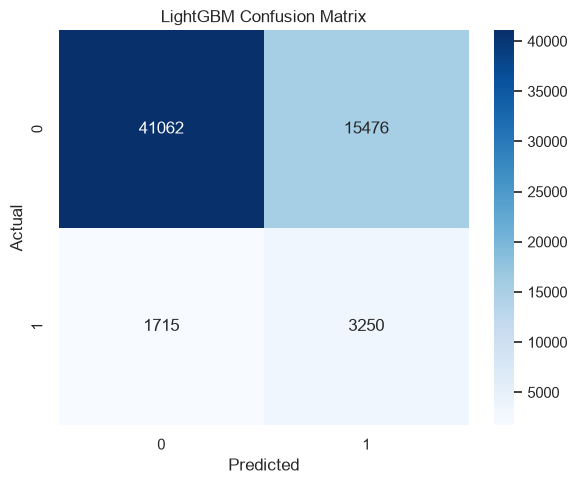

In [7]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("LightGBM Confusion Matrix")

plt.tight_layout()

plt.show()

# Classification Report

In [8]:
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.17      0.65      0.27      4965

    accuracy                           0.72     61503
   macro avg       0.57      0.69      0.55     61503
weighted avg       0.90      0.72      0.78     61503



# ROC Curve

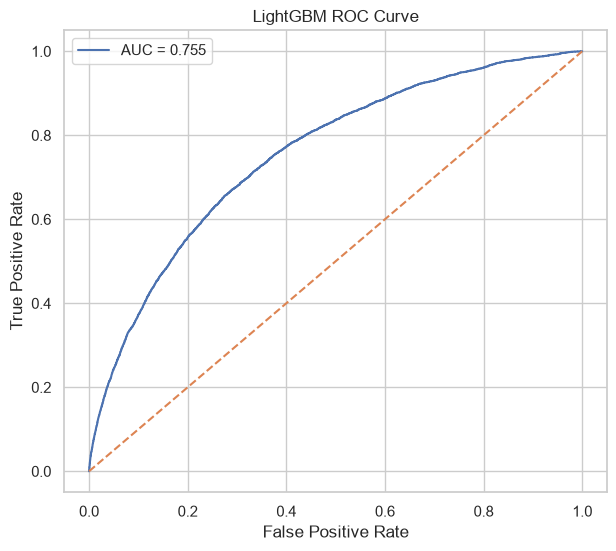

In [9]:
fpr,tpr,_ = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("LightGBM ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Feature Importance

LightGBM estimates feature importance based on the contribution of each principal component to reducing the training loss.

The most influential principal components are identified below.

In [10]:
feature_importance = (

    pd.DataFrame({

        "Feature":X_train.columns,

        "Importance":lgbm_model.feature_importances_

    })

    .sort_values(
        "Importance",
        ascending=False
    )

)

feature_importance.head(15)

,Feature,Importance
7,PC8,255
19,PC20,231
8,PC9,230
30,PC31,218
28,PC29,211
1,PC2,210
17,PC18,194
107,PC108,186
2,PC3,180
5,PC6,174


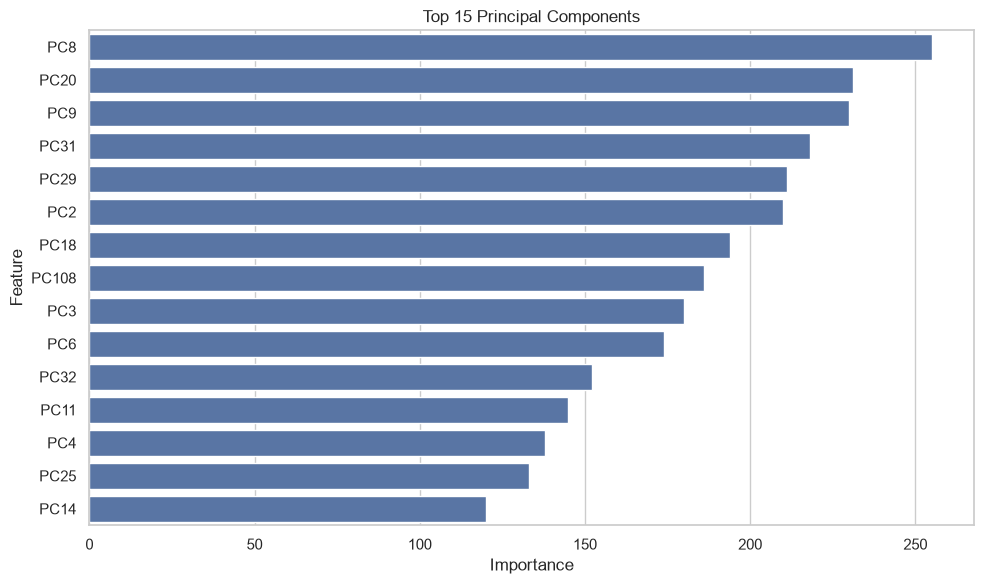

In [11]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=feature_importance.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Top 15 Principal Components")

plt.tight_layout()

plt.show()

# Model Configuration

The LightGBM classifier was trained using:

- Number of Trees = 300
- Learning Rate = 0.05
- Maximum Tree Depth = 6
- Subsample = 0.80
- Column Sample by Tree = 0.80
- Class Weight = Balanced using `scale_pos_weight`

These parameters improve model performance while addressing class imbalance.

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [13]:
# ============================================================
# Save LightGBM Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    lgbm_model,
    MODEL_DIR / "lightgbm_model.pkl"
)

print("LightGBM model saved successfully.")

LightGBM model saved successfully.


# Save Model Performance

The evaluation metrics of the LightGBM classifier are appended to the common model results file for comparison with all previously developed machine learning models.

In [12]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["LightGBM"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,LightGBM,0.720485,0.173555,0.654582,0.274366,0.754543,15476,1715,3250,41062


# Conclusion

The LightGBM classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- A gradient boosting model optimized for large-scale structured datasets was developed.
- Performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Feature importance analysis identified the principal components contributing most to loan default prediction.
- The confusion matrix and ROC curve demonstrated the model's classification capability.
- Performance metrics were recorded for comparison with all previous machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 13 – Model Comparison, Credit Risk Score Generation, and Fairness Analysis**